# Jupyter-Notebook zur Vorlesungsbegleitung k-Nearest Neighbor


Zuerst werden Bibliotheken geladen, welche in diesem Notebook verwendet werden

In [1]:
import numpy as np
import matplotlib.pyplot as plt
import sklearn

import pandas as pd


Zur veranschaulichung wird der *Iris*-Datensatz verwendet. Dieser ist in sklearn integriert kann direkt geladen werden: 

In [2]:
from sklearn.datasets import load_iris
iris_dataset = load_iris()

In [3]:
# load_iris() gibt ein Dictionary mit folgendem Inhalt:

print("Keys of iris_datatset:\n {}".format(
    iris_dataset.keys()))

Keys of iris_datatset:
 dict_keys(['data', 'target', 'frame', 'target_names', 'DESCR', 'feature_names', 'filename', 'data_module'])


In [4]:
print(iris_dataset['DESCR'])  #DESCR beinhaltet einen Beschreibung des Datensatzes. Diese betrachten wir 

.. _iris_dataset:

Iris plants dataset
--------------------

**Data Set Characteristics:**

:Number of Instances: 150 (50 in each of three classes)
:Number of Attributes: 4 numeric, predictive attributes and the class
:Attribute Information:
    - sepal length in cm
    - sepal width in cm
    - petal length in cm
    - petal width in cm
    - class:
            - Iris-Setosa
            - Iris-Versicolour
            - Iris-Virginica

:Summary Statistics:

============== ==== ==== ======= ===== ====================
                Min  Max   Mean    SD   Class Correlation
============== ==== ==== ======= ===== ====================
sepal length:   4.3  7.9   5.84   0.83    0.7826
sepal width:    2.0  4.4   3.05   0.43   -0.4194
petal length:   1.0  6.9   3.76   1.76    0.9490  (high!)
petal width:    0.1  2.5   1.20   0.76    0.9565  (high!)
============== ==== ==== ======= ===== ====================

:Missing Attribute Values: None
:Class Distribution: 33.3% for each of 3 classes.
:Cr

In [5]:
print(iris_dataset['data'].shape) # Gibt den shape der Merkmalmatrix aus. Der Datensatz beinhaltet 150 Merkmalvektoren, mit je 4 Merkmalen. Siehe Beschreibung.
print(iris_dataset['target'].shape) # Gibt den shape des labels-Array aus. Fuer jeden der 150 Merkmalvektoren existiert ein Label
print(iris_dataset['target']) # Die Labels werden hier ausgegeben. Insgesamt existieren 3 Klassen, Jeweils 50 Merkmalvektoren pro Klasse.

print(iris_dataset['target_names']) # hier werden die Klarnamen der Klassen ausgegeben. Details findet man oben in der Beschreibung.



(150, 4)
(150,)
[0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0
 0 0 0 0 0 0 0 0 0 0 0 0 0 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1
 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 2 2 2 2 2 2 2 2 2 2 2
 2 2 2 2 2 2 2 2 2 2 2 2 2 2 2 2 2 2 2 2 2 2 2 2 2 2 2 2 2 2 2 2 2 2 2 2 2
 2 2]
['setosa' 'versicolor' 'virginica']


## Datenanalyse mittels pandas


Die Daten des Iris-Corpus werden in ein pandas-DateFrame geladen. Anschliessend werden die Daten geplottet. 
In den Spalten und Zeilen werden jeweils die vier Merkmale gegenuebergestellt.
In der Diagonalen des Plots befinden sich jeweils die Histogramme der Daten. Diese geben an wie haeufig ein bestimmter Datenwert eines Merkmals vorkommt (https://de.wikipedia.org/wiki/Histogramm). Damit kann man die Verteilung der Merkmale analysieren und bewerten. Idealerweise haben Merkmale eine noormalverteiltes Auftreten.

Die Nicht-Diagonalelemente des Plots, plotten jeweils ein Merkmal auf der x-Achse, ein Merkmal auf der y-Achse. Die Einfaerbung wird durch den Parameter c= festgelegt (hier kommen die Farben also aus den labels des Datensatzes). Damit laesst sich der Zusammenhang zweiter Merkmal, bzw. deren Korrelation (https://de.wikipedia.org/wiki/Korrelation) analysieren. Bei der Klassifikation ist das Ziel, moegichst unterschiedliche Merkmale zu verwenden, die geringen linearen Zusammenhang zeigen, also eine geringe Korrelation besitzen. 

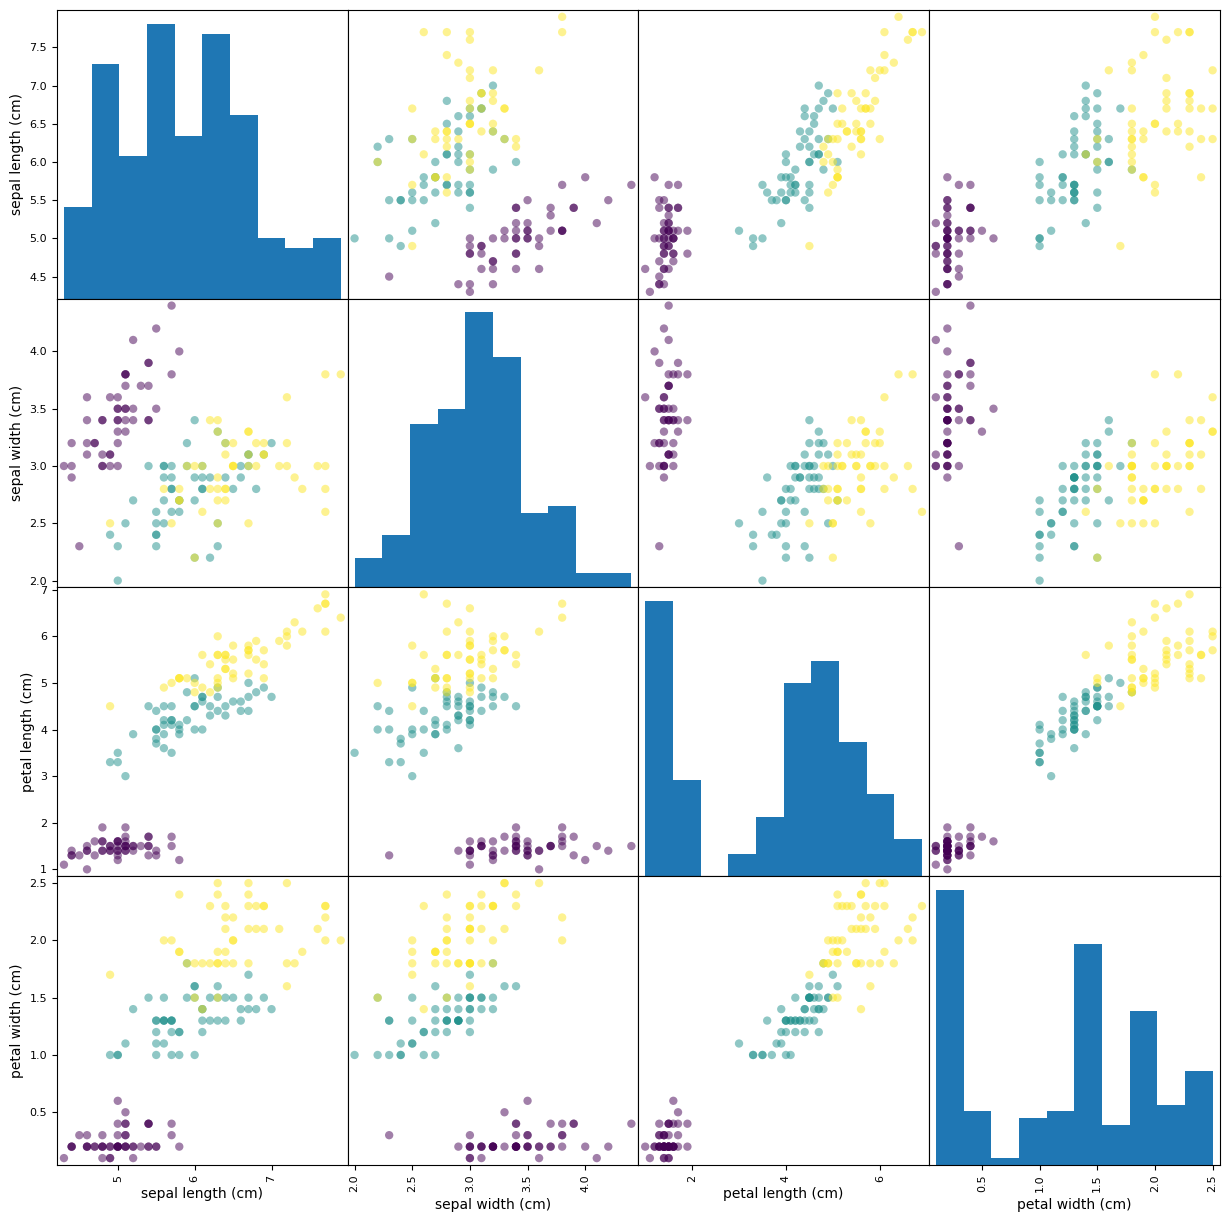

In [6]:
iris_dataframe = pd.DataFrame(iris_dataset['data'], 
                              columns=iris_dataset.feature_names)
grr = pd.plotting.scatter_matrix(
    iris_dataframe, c=iris_dataset['target'], figsize=(15,15), marker='o' )


## Unser erstes Klassifikationsexperiment

Fuer unser erstes Klassifikationsexperiment nutzen wir die Iris-Daten und den K-Nearest Neighbor Klassifikator aus sklearn.
Klassifikation ist ein ueberwachtes Lernverfahren, wir benoetigen also Daten mit zugehoerigen Klassenlabels.

In [27]:
from sklearn.neighbors import KNeighborsClassifier  #laedt den Klassifikator 
knn = KNeighborsClassifier(n_neighbors=21)  # knn-Objekt wird erzeugt, das k (die Anzahl) der Nachbarn wird auf 1 gesetzt

X=iris_dataset['data'][:,[0,1]] # wir nehmen die ersten beiden Merkmale aus den Iris-Daten und speichern diese in der Matrix X

print(X.shape)                  # zur Ueberpruefung: X enthaelt 150 Zeilen und 2 Spalten
y=iris_dataset['target']        # Die labels, die zum Training noetig sind, werden in ein array y gespeichert.

knn.fit(X,y)                    # mittels der fit-Methode, wird der Klassifikator trainiert. fit benoetigt Daten (X) und labels (y).  
                                # predict wird spaeter zur Erkennung benutzt. fit() & predict() wird in sklearn fuer alle Klassifikatoren verwendet (siehe https://scikit-learn.org/stable/tutorial/basic/tutorial.html#learning-and-predicting)

(150, 2)


,n_neighbors,21
,weights,'uniform'
,algorithm,'auto'
,leaf_size,30
,p,2
,metric,'minkowski'
,metric_params,None
,n_jobs,None


Nachfolgend plotten wir den trainierten Klassifikator:

(2464, 2)


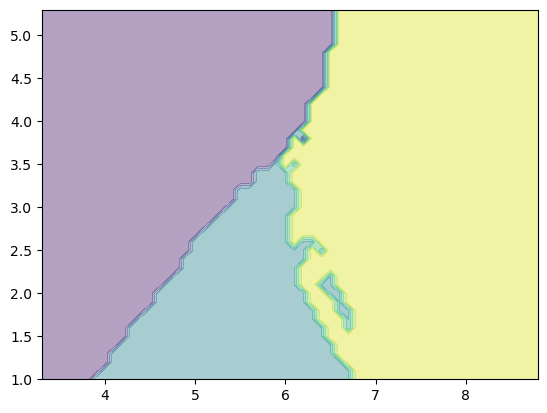

In [28]:
x1_min,x1_max = X[:,0].min() -1, X[:,0].max()+1    # fuer beide Merkmale werden min- und max-Werte bestimmt.  
x2_min,x2_max = X[:, 1].min() -1 , X[:,1].max()+1  

xx1,xx2 = np.meshgrid(np.arange(x1_min,x1_max,0.1), np.arange(x2_min,x2_max,0.1))  
#Aus den mix/max-Werten, werden zuerst Arrays erzeugt mittel arange. x_min ist der Start-Wert, x_max der End-Wert, die Schrittweite ist 0.1
#Daraus werden dann die Matrizen xx1 und xx2 durch meshgrid erzeugt um den moeglichen Merkmalraum zu erzeugen 

example_vecs=np.c_[xx1.ravel(), xx2.ravel()] #xx1 und xx2 werden zuerst in arrays "geflacht" mittels ravel(). 
                                                    # c_() erzeugt anschliessend aus den Daten jeweils Wertepaare, welche moeglichen Merkmalvektoren entsprechen
print(example_vecs.shape)  #2464 Vektoren

Z=knn.predict(example_vecs)  #Klassen der erzeugten Beispielvektoren werden mittels predict() bestimmt
Z = Z.reshape(xx1.shape) #Das array Z wird in den shape von xx1,bzw xx2 gebracht 

plt.contourf(xx1,xx2,Z,alpha=0.4) #Erzeugt einen Contour-plot der Punkte xx1 und xx2 mit den erkannten labels Z

#plt.scatter(X[:,0],X[:,1],c=iris_dataset.target ,s=20,edgecolor='k')  # mit diesem Befehl koennen die eigentlich Datenpunkte, mit denen der kNN-Klassifikator trainiert wurde geplottet werrden

plt.show()


## Fragen

- Oben haben wir die Merkmale 0 und 1, welchen septal length und septal width entsprechen, zum Training des Klassifikator verwendet. Was muss man anpassen, um andere Merkmale zu verwenden?
- Welche Merkmale korrelieren wenig miteinander und sind gut geeignet?
- Welche Auswirkung hat die Erhöhung/Verringerung des Parameters k des kNN-Klassifikators (im Moment: n_neighbors=1)

In [9]:
knn = KNeighborsClassifier(n_neighbors=1)
#X=iris_dataset['data'][:,[0,1]] # wir nehmen die ersten beiden Merkmale aus den Iris-Daten und speichern diese in der Matrix X
X=iris_dataset['data']

print(X.shape)                  # zur Ueberpruefung: X enthaelt 150 Zeilen und 2 Spalten
y=iris_dataset['target']        # Die labels, die zum Training noetig sind, werden in ein array y gespeichert.

knn.fit(X,y)                    # mittels der fit-Methode, wird der Klassifikator trainiert. fit benoetigt Daten (X) und labels (y).  
                                # predict wird spaeter zur Erkennung benutzt. fit() & predict() wird in sklearn fuer alle Klassifikatoren verwendet (siehe https://scikit-learn.org/stable/tutorial/basic/tutorial.html#learning-and-predicting)

(150, 4)


,n_neighbors,1
,weights,'uniform'
,algorithm,'auto'
,leaf_size,30
,p,2
,metric,'minkowski'
,metric_params,None
,n_jobs,None


# Evaluation von Klassifiktoren


In diesem Abschnitt wird die Evaluation von Klassifikatoren behandelt. 
Zuerst werden die Evaluationsmaße aus der Vorlesung betrachtet, anschließend die Evaluationsmethoden. 

## Evaluationsmaße

sklearn besitzt Funktionen zur Evaluation, die denen der Vorlesung entsprechen. Eine vollstaendige Liste finden Sie hier: https://scikit-learn.org/stable/modules/classes.html#sklearn-metrics-metrics



Die Akkuratheit wird bestimmt mittels:


In [10]:
pred=knn.predict(X)            # Fuer den Datensatz X, werden Klassen vorhergesagt
print(sklearn.metrics.accuracy_score(y,pred)) #Die Akkuratheit 


1.0


sklearn bietet die Moeglichkeit eines *classification_reports*. Dieser gibt pro Klasse Precision, Recall, und f1-score an

In [11]:

eval=sklearn.metrics.classification_report(y,pred)
print(eval)


              precision    recall  f1-score   support

           0       1.00      1.00      1.00        50
           1       1.00      1.00      1.00        50
           2       1.00      1.00      1.00        50

    accuracy                           1.00       150
   macro avg       1.00      1.00      1.00       150
weighted avg       1.00      1.00      1.00       150



Die Verwechslungsmatrix ist verfuegbar in *sklearn.metrics.confusion_matrix*

In [12]:

confMat=sklearn.metrics.confusion_matrix(y, pred)
print(confMat)


[[50  0  0]
 [ 0 50  0]
 [ 0  0 50]]


# Einsetzen von einem Train/Test Split

Zur sinnvollen Evaluation muss der Datensatz in train und test geteilt werden. Diese muessen disjunk sein.
Auf den Trainingsdaten wird der Klassifikator trainiert, auf den Testddaten getestet. Geschieht dies nicht und der Klassifikator wird auf den selben Daten trainiert und getestet, hat die Evaluation keine Aussagekraft. Laut den Zahlen, wird ihr KLassifikator   hervorragend funktionieren. Die Generalisierungsfaehigkeit kann aber nicht getestet werden.

## Training auf dem Train-Subset

In [13]:
from sklearn.model_selection import train_test_split

X_train, X_test, y_train,y_test  = train_test_split(iris_dataset['data'][:,[0,1]],iris_dataset['target'])


knnTrainTest = KNeighborsClassifier(n_neighbors=1)
knnTrainTest.fit(X_train,y_train)



,n_neighbors,1
,weights,'uniform'
,algorithm,'auto'
,leaf_size,30
,p,2
,metric,'minkowski'
,metric_params,None
,n_jobs,None


## Evaluation auf dem Test-Subset

In [14]:
pred=knnTrainTest.predict(X_test)
print(sklearn.metrics.accuracy_score(y_test,pred))


0.8157894736842105


In [15]:
#eval=sklearn.metrics.classification_report(iris_dataset.target,pred)
#print(eval)
#confMat=sklearn.metrics.confusion_matrix(iris_dataset.target, pred)
#print(confMat)

eval = sklearn.metrics.classification_report(y_test,pred)
print(eval)
confMat = sklearn.metrics.confusion_matrix(y_test,pred)
print(confMat)

              precision    recall  f1-score   support

           0       1.00      1.00      1.00        16
           1       0.70      0.64      0.67        11
           2       0.67      0.73      0.70        11

    accuracy                           0.82        38
   macro avg       0.79      0.79      0.79        38
weighted avg       0.82      0.82      0.82        38

[[16  0  0]
 [ 0  7  4]
 [ 0  3  8]]


# Kreuzvalidierung

Die Kreuzvalidierung eignet sich besonders fuer kleine Datensaetze. Der Datensatz wird in folds geteilt, beispielsweise 10 folds.
Der Klassifikator wird jeweils auf 9 folds trainiert, und auf dem verbleibenden getestet. Dieses Vorgehen wird so oft widerholt, bis jedes fold einmal zim Test verwendet wurde.

In [16]:
from sklearn.model_selection import cross_validate


model=KNeighborsClassifier(n_neighbors=1)

cv_results = cross_validate(model, X, y, cv=10)
print(cv_results['test_score'])
avg_score = np.average(cv_results['test_score'])

print("avg_score=%.2f%% " % ( avg_score * 100,))

[1.         0.93333333 1.         0.93333333 0.86666667 1.
 0.86666667 1.         1.         1.        ]
avg_score=96.00% 


## stratified


Durch die *stratified*  Variante der Kreuzvalidierung wird die statistische Gegebenheit des Datensatzes in den folds beigehalten. 
Das eignet sich besonders, wenn die Haeufigkeiten der Klassen nicht gleichverteilt sind. 


Das wird folgendermaßen in sklearn verwendet:

In [17]:
from sklearn.model_selection import StratifiedKFold


skf = StratifiedKFold(n_splits=10)
model=KNeighborsClassifier(n_neighbors=1)
accuracies=[]

for train_indices, test_indices in skf.split(X, y):
    #print("TRAIN:", train_indices, "TEST:", test_indices)
    model.fit(X[train_indices],y[train_indices])
    accuracies.append(model.score(X[test_indices],y[test_indices]))
    #print(accuracies[-1])

print("avg_score of stratified=%.2f%%" %np.average(accuracies))


avg_score of stratified=0.96%


## LeaveOneOut


Leave-one-out ist eine weitere Variante der Kreuzvalidierung. Hier wird jedes Sample einzeln betrachtet.
Jedes sample wird einmal zum Testen verwendet, alle anderen Sample werden zum Training benutzt.

In [18]:
from sklearn.model_selection import LeaveOneOut

loo = LeaveOneOut()
model=KNeighborsClassifier(n_neighbors=1)
accuracies=[]

for train_indices, test_indices in loo.split(X, y):
    #print("TRAIN:", train_indices, "TEST:", test_indices)
    model.fit(X[train_indices],y[train_indices])
    accuracies.append(model.score(X[test_indices],y[test_indices]))
    #print(accuracies[-1])

print("avg_score of stratified=%.2f%%" %np.average(accuracies))


avg_score of stratified=0.96%
